# NYC traffic safety: what changed around major policy milestones?

**Research question:** How did reported crash frequency, injury burden, and fatalities change around Vision Zero, the COVID disruption, and the expansion to 24/7 speed cameras?

This is an **exploratory policy analysis**, not a randomized experiment. We look for changes that coincide with the events, check alternative explanations, and distinguish a descriptive pattern from a credible policy effect. An initiative can change both travel and reporting, and fewer reports do not necessarily mean fewer serious injuries.

**How to use this notebook:** run the cells in order. Each code cell has a preceding explanation; charts and numerical interpretations are generated from the actual data. Figures, combined analysis tables, a source manifest, and presentation notes are saved automatically. The companion `.py` file uses Jupyter `# %%` cells and contains the same analysis.

**Outcomes:** all police-reported crashes; crashes with at least one injured or killed person (called **harm crashes** below); people injured; and people killed. These are vehicle-involved collisions, not a passenger-car-only sample. Fatalities in this preliminary collision table can differ from final official traffic-fatality statistics.

## 1. Setup and reproducible file locations
Install dependencies once with `%pip install -r ../requirements-analysis.txt` when the notebook is opened from the notebooks folder (use `requirements-analysis.txt` from the repository root), then restart the kernel.

We use pandas for data preparation, Matplotlib for presentation figures, and statsmodels for transparent count regressions. No raw crash records are printed.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from urllib.request import urlretrieve
import hashlib
import json
import sys
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display, Markdown
from IPython import get_ipython

if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
DATA = ROOT / 'data'
OUT = ROOT / 'outputs/policy_analysis'
PROCESSED = DATA / 'processed'
OUT.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 200, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.grid': True, 'grid.alpha': 0.15})
BLUE, ORANGE, RED, GREEN = '#2563eb', '#ea580c', '#dc2626', '#15803d'
FIGURES = []
FINDINGS = []

def save_figure(fig, name):
    fig.savefig(OUT / f'{name}.png', bbox_inches='tight', facecolor='white')
    FIGURES.append(name)
    plt.show()
    plt.close(fig)

def note(text):
    FINDINGS.append(text)
    display(Markdown(text))

print('Python:', platform.python_version(), '| pandas:', pd.__version__, '| statsmodels:', sm.__version__)

Python: 3.14.7 | pandas: 3.0.6 | statsmodels: 0.15.0


## 2. Fetch the newest GitHub inputs, verify, and unzip
We fetched `main` on October 17, 2026 and pinned commit `f92bea87dff7ee7a57e41b4af85535f571d1f5a1`. The data folder now includes **Combined_Traffic_Volume_Counts_hourly.zip**, combining historical and automated hourly traffic counts. The collision and street archives are unchanged.

Archives are verified against their Git blob hashes before safe CSV extraction. A manifest records the pinned URLs, hashes, and extracted files.

In [2]:
COMMIT = 'f92bea87dff7ee7a57e41b4af85535f571d1f5a1'
REPOSITORY = 'https://github.com/ericmao2007/SSMU-Data-Challenge-I'
ARCHIVES = [
    ('other/Combined_Traffic_Volume_Counts_hourly.zip', 'b4d8087675f8c0a2816a5e82a2d24b7e0f10fb4f'),
    ('motor_vehicle_collisions.zip', 'f2dccb6531a04f13251f024a11d99298e3346139'),
    ('other/NYC_Street_Geospatial.zip', '22dc4e7c1ca429428cc60a3c1ecd53fb804ce188'),
]
manifest = {'repository': REPOSITORY, 'commit': COMMIT, 'checked_on': '2026-10-17',
            'python': platform.python_version(), 'pandas': pd.__version__,
            'statsmodels': sm.__version__, 'files': []}
for relative, expected_blob in ARCHIVES:
    archive = DATA / relative
    archive.parent.mkdir(parents=True, exist_ok=True)
    url = f'https://raw.githubusercontent.com/ericmao2007/SSMU-Data-Challenge-I/{COMMIT}/data/{relative}'
    if not archive.exists():
        urlretrieve(url, archive)
    blob = hashlib.sha1(f'blob {archive.stat().st_size}\0'.encode())
    sha256 = hashlib.sha256()
    with archive.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            blob.update(block)
            sha256.update(block)
    assert blob.hexdigest() == expected_blob, f'Archive version differs: {relative}'
    extracted = []
    with ZipFile(archive) as zipped:
        for item in zipped.infolist():
            if not item.filename.endswith('.csv') or item.filename.startswith('__MACOSX/'):
                continue
            target = (archive.parent / item.filename).resolve()
            assert target.is_relative_to(archive.parent.resolve()), 'Unsafe archive member'
            if not target.exists() or target.stat().st_size != item.file_size:
                zipped.extract(item, archive.parent)
            extracted.append(str(target.relative_to(ROOT)))
    manifest['files'].append({'path': str(archive.relative_to(ROOT)), 'url': url,
                              'git_blob': expected_blob, 'sha256': sha256.hexdigest(),
                              'extracted': extracted})
(OUT / 'source_manifest.json').write_text(json.dumps(manifest, indent=2))
display(pd.DataFrame(manifest['files'])[['path', 'git_blob', 'extracted']])

,path,git_blob,extracted
0,data/other/Combined_Traffic_Volume_Counts_hour...,b4d8087675f8c0a2816a5e82a2d24b7e0f10fb4f,[data/other/Combined_Traffic_Volume_Counts_hou...
1,data/motor_vehicle_collisions.zip,f2dccb6531a04f13251f024a11d99298e3346139,[data/motor_vehicle_collisions.csv]
2,data/other/NYC_Street_Geospatial.zip,22dc4e7c1ca429428cc60a3c1ecd53fb804ce188,[data/other/NYC_Street_Geospatial.csv]


## 3. A policy calendar, including changes to the measurement system
Dates are verified against primary government sources, not inferred from the crash graph. The policy table is exported to `data/processed/policy_calendar.csv`; figures mark the key dates.

- [Vision Zero announcement, January 15, 2014](https://www.nyc.gov/site/dcas/about/press-releases/jan-15-2014-press-release.page): a package of measures, not a single instantaneous treatment.
- [Default limit reduced to 25 mph, November 7, 2014](https://www.nyc.gov/html/dot/html/pr2014/pr14-085.shtml).
- [Crash recording system changed in March 2016](https://data.cityofnewyork.us/Public-Safety/NYC-Motor-Vehicle-Incident-Map/g52p-mz8y): a measurement-system change to consider in sensitivity checks.
- [NYS on PAUSE, March 22, 2020](https://www.nycourts.gov/reporter/webdocs/GovCuomoPAUSE.pdf); [NYC reopening phase one, June 8, 2020](https://www.governor.ny.gov/news/new-york-city-enters-phase-one-reopening-today-governor-cuomo-announces-new-york-city-now).
- [NYPD non-injury reporting change, April 6, 2020](https://www.nyc.gov/site/nypd/services/vehicles-property/non-injury-vehicle-collisions.page): a major reason not to call the 2020 drop in total reports a pure safety effect.
- [Speed cameras expanded to 24/7, August 1, 2022 at 10 p.m.](https://www.nyc.gov/mayors-office/news/2022/08/mayor-adams-flips-switch-turns-speed-cameras-24-7). Previously enforceable hours were weekdays, 6 a.m.–10 p.m. The comparison concerns hours, not a map of camera installation sites.
- [Congestion pricing began January 5, 2025](https://www.governor.ny.gov/news/six-months-governor-hochul-highlights-success-congestion-pricing-traffic-down-business-and). This is shown as context; a citywide change is not a zone-specific evaluation.

In [3]:
policies = pd.DataFrame([
    ('Vision Zero announced', '2014-01-15', 'policy'),
    ('25 mph default limit', '2014-11-07', 'policy'),
    ('FORMS recording system', '2016-03-01', 'measurement'),
    ('NYS on PAUSE', '2020-03-22', 'disruption'),
    ('Non-injury reporting change', '2020-04-06', 'measurement'),
    ('NYC phase-one reopening', '2020-06-08', 'disruption'),
    ('24/7 speed cameras', '2022-08-01', 'policy'),
    ('Congestion pricing', '2025-01-05', 'policy'),
], columns=['event', 'date', 'type'])
policies['date'] = pd.to_datetime(policies['date'])
policies.to_csv(PROCESSED / 'policy_calendar.csv', index=False)
display(policies)

,event,date,type
0,Vision Zero announced,2014-01-15,policy
1,25 mph default limit,2014-11-07,policy
2,FORMS recording system,2016-03-01,measurement
3,NYS on PAUSE,2020-03-22,disruption
4,Non-injury reporting change,2020-04-06,measurement
5,NYC phase-one reopening,2020-06-08,disruption
6,24/7 speed cameras,2022-08-01,policy
7,Congestion pricing,2025-01-05,policy


## 4. Prepare the new street inventory without making a misleading join
Despite its filename, the street table covers **all New York State**, and the CSV has no actual line geometry. We retain the five NYC counties. A documented street-name normalization plus borough creates a conservative **many-to-one street-context join**, not an exact crash-to-road-segment match.

The [state dictionary](https://gis.ny.gov/system/files/documents/2023/07/streets_data_dictionary.pdf) defines `SPEED` as average travel speed. It is a snapshot attribute, not the legal speed limit at the crash date. We call it **inventory speed** and never use it to identify whether a crash received the 2014 speed-limit treatment. Ambiguous road speeds are flagged; unmatched crashes remain in every citywide analysis.

In [4]:
COUNTY_TO_BOROUGH = {'NEW YORK': 'MANHATTAN', 'KINGS': 'BROOKLYN', 'QUEENS': 'QUEENS',
                     'BRONX': 'BRONX', 'RICHMOND': 'STATEN ISLAND'}

def canonical_street(series):
    result = series.fillna('').astype('string').str.upper()
    result = result.str.replace(r'[^A-Z0-9 ]', ' ', regex=True)
    result = result.str.replace(r'\b(\d+)(ST|ND|RD|TH)\b', r'\1', regex=True)
    substitutions = {'AVENUE': 'AVE', 'STREET': 'ST', 'BOULEVARD': 'BLVD', 'ROAD': 'RD',
                     'DRIVE': 'DR', 'PLACE': 'PL', 'PARKWAY': 'PKWY', 'EXPRESSWAY': 'EXPY',
                     'HIGHWAY': 'HWY', 'NORTH': 'N', 'SOUTH': 'S', 'EAST': 'E', 'WEST': 'W'}
    for word, short in substitutions.items():
        result = result.str.replace(rf'\b{word}\b', short, regex=True)
    return result.str.replace(r'\s+', ' ', regex=True).str.strip()

street_columns = ['OBJECTID', 'CompleteStreetName', 'LeftCountyName', 'RightCountyName',
                  'SPEED', 'OneWay', 'FCC', 'DateModified']
street = pd.read_csv(DATA / 'other/NYC_Street_Geospatial.csv', usecols=street_columns, low_memory=False)
statewide_street_rows = len(street)
left_borough = street['LeftCountyName'].str.upper().map(COUNTY_TO_BOROUGH)
right_borough = street['RightCountyName'].str.upper().map(COUNTY_TO_BOROUGH)
street['borough'] = left_borough.fillna(right_borough)
street = street.loc[street['borough'].notna()].copy()
street['street_key'] = canonical_street(street['CompleteStreetName'])
street['inventory_speed'] = pd.to_numeric(street['SPEED'], errors='coerce').where(lambda x: x.gt(0))
road_lookup = street.groupby(['borough', 'street_key']).agg(
    inventory_speed=('inventory_speed', 'median'),
    speed_values=('inventory_speed', 'nunique'), inventory_segments=('OBJECTID', 'size'),
).reset_index()
assert not road_lookup.duplicated(['borough', 'street_key']).any()
road_lookup.to_csv(PROCESSED / 'nyc_street_context_lookup.csv', index=False)
display(pd.Series({'Statewide inventory rows': statewide_street_rows, 'NYC inventory rows': len(street),
                  'NYC borough/street keys': len(road_lookup),
                  'Keys with multiple inventory speeds': int(road_lookup.speed_values.gt(1).sum())}).to_frame('count'))
del street

,count
Statewide inventory rows,1097338
NYC inventory rows,143410
NYC borough/street keys,12333
Keys with multiple inventory speeds,1458


## 5. Combine crashes, street context, and policy flags
We process the collision file in chunks to control memory. Collision IDs are checked globally for duplicates. Missing outcome values remain unknown, and negative counts are rejected. We count harm crashes only where injury/fatality status is known; we also count the missing statuses.

The street join cannot multiply crash rows because `validate='many_to_one'` enforces the intended relationship. We keep unknown boroughs as an explicit category. Valid crash times identify **newly enforceable camera hours**: all weekend hours and weekday hours before 6 a.m. or at/after 10 p.m. Missing times are excluded only from that analysis.

Output tables combine the sources at usable analysis scales: day, month, borough, camera-hour group, and inventory-speed category. No traffic-volume denominator is assumed here.

**Quality screen:** retain all records in the exported panels, but exclude months with more than 0.1% missing injury or fatality fields from the main monthly plots and models. This declared completeness screen prevents the poorly populated 2026 endpoint from appearing as a real collapse in harm. Very small incidental missingness in earlier months is reported in the audit; counts are sums of observed values, not imputations.

In [5]:
OUTCOME_COLUMNS = {
    'NUMBER OF PERSONS INJURED': 'injured', 'NUMBER OF PERSONS KILLED': 'killed',
    'NUMBER OF PEDESTRIANS INJURED': 'ped_injured', 'NUMBER OF PEDESTRIANS KILLED': 'ped_killed',
    'NUMBER OF CYCLIST INJURED': 'cyclist_injured', 'NUMBER OF CYCLIST KILLED': 'cyclist_killed',
    'NUMBER OF MOTORIST INJURED': 'motorist_injured', 'NUMBER OF MOTORIST KILLED': 'motorist_killed',
}
usecols = ['COLLISION_ID', 'CRASH DATE', 'CRASH TIME', 'BOROUGH', 'ON STREET NAME', *OUTCOME_COLUMNS]
ids = pd.read_csv(DATA / 'motor_vehicle_collisions.csv', usecols=['COLLISION_ID'])
duplicate_ids = int(ids['COLLISION_ID'].duplicated().sum())
assert duplicate_ids == 0, 'Duplicate collision IDs require an explicit deduplication decision.'
del ids
parts, by_borough, by_camera, by_road = [], [], [], []
audit = {'raw_crashes': 0, 'invalid_dates': 0, 'missing_time': 0,
         'unknown_harm_status': 0, 'street_matched': 0, 'street_eligible': 0,
         'ambiguous_speed_matches': 0, 'unknown_borough': 0}
for chunk in pd.read_csv(DATA / 'motor_vehicle_collisions.csv', usecols=usecols, chunksize=200_000):
    audit['raw_crashes'] += len(chunk)
    chunk['date'] = pd.to_datetime(chunk['CRASH DATE'], format='mixed', errors='coerce').dt.normalize()
    audit['invalid_dates'] += int(chunk.date.isna().sum())
    chunk = chunk.loc[chunk.date.notna()].copy()
    chunk['borough'] = chunk['BOROUGH'].fillna('UNKNOWN').str.upper().str.strip()
    chunk['street_key'] = canonical_street(chunk['ON STREET NAME'])
    before = len(chunk)
    chunk = chunk.merge(road_lookup, on=['borough', 'street_key'], how='left', validate='many_to_one')
    assert len(chunk) == before
    audit['street_eligible'] += int(chunk.borough.ne('UNKNOWN').sum())
    audit['street_matched'] += int(chunk.inventory_segments.notna().sum())
    audit['ambiguous_speed_matches'] += int(chunk.speed_values.gt(1).sum())
    audit['unknown_borough'] += int(chunk.borough.eq('UNKNOWN').sum())
    for original, short in OUTCOME_COLUMNS.items():
        values = pd.to_numeric(chunk[original], errors='coerce')
        assert not values.lt(0).any(), f'Negative count in {original}'
        chunk[short] = values
    known = chunk['injured'].notna() & chunk['killed'].notna()
    chunk['harm_crashes'] = (chunk['injured'].gt(0) | chunk['killed'].gt(0)).astype(float).where(known)
    chunk['non_harm_crashes'] = (chunk['injured'].eq(0) & chunk['killed'].eq(0)).astype(float).where(known)
    chunk['crashes'] = 1
    chunk['known_harm'] = known.astype(int)
    chunk['known_injured'] = chunk.injured.notna().astype(int)
    chunk['known_killed'] = chunk.killed.notna().astype(int)
    audit['unknown_harm_status'] += int((~known).sum())
    chunk['hour'] = pd.to_datetime(chunk['CRASH TIME'], format='%H:%M', errors='coerce').dt.hour
    audit['missing_time'] += int(chunk.hour.isna().sum())
    weekend = chunk.date.dt.dayofweek.ge(5)
    chunk['new_hours'] = (weekend | chunk.hour.lt(6) | chunk.hour.ge(22)).astype(int)
    measures = ['crashes', 'harm_crashes', 'non_harm_crashes', 'known_harm',
                'known_injured', 'known_killed', *OUTCOME_COLUMNS.values()]
    parts.append(chunk.groupby('date')[measures].sum(min_count=1))
    by_borough.append(chunk.groupby(['date', 'borough'])[measures].sum(min_count=1))
    by_camera.append(chunk.loc[chunk.hour.notna()].groupby(['date', 'new_hours'])[measures].sum(min_count=1))
    chunk['month'] = chunk.date.dt.to_period('M').dt.to_timestamp()
    # Preserve unknown and ambiguous inventory classifications instead of guessing a segment.
    chunk['road_context'] = np.select(
        [chunk.inventory_segments.isna(), chunk.inventory_speed.isna(), chunk.speed_values.gt(1),
         chunk.inventory_speed.le(25), chunk.inventory_speed.le(35)],
        ['Unmatched', 'Matched, no speed value', 'Mixed inventory speeds', 'Inventory speed 25 or lower',
         'Inventory speed 26–35'],
        default='Inventory speed above 35')
    by_road.append(chunk.groupby(['month', 'road_context'])[measures].sum(min_count=1))

daily = pd.concat(parts).groupby(level=0).sum(min_count=1).sort_index()
assert daily.crashes.sum() == audit['raw_crashes'] - audit['invalid_dates']
# Empty-status days reconcile to zero *known* records; their outcomes stay NaN.
assert (daily.harm_crashes.fillna(0) + daily.non_harm_crashes.fillna(0) == daily.known_harm).all()
first_date, last_date = daily.index.min(), daily.index.max()
assert len(daily) == len(pd.date_range(first_date, last_date)), 'Missing entire crash dates need review.'
monthly = daily.resample('MS').sum(min_count=1)
monthly['observed_days'] = daily['crashes'].resample('MS').size()
monthly['calendar_days'] = monthly.index.days_in_month
monthly['complete_month'] = monthly.observed_days.eq(monthly.calendar_days)
monthly['injury_field_coverage'] = monthly.known_injured / monthly.crashes
monthly['fatality_field_coverage'] = monthly.known_killed / monthly.crashes
monthly['complete_outcomes'] = monthly.injury_field_coverage.ge(.999) & monthly.fatality_field_coverage.ge(.999)
monthly['month_of_year'] = monthly.index.month
borough_daily = pd.concat(by_borough).groupby(level=[0, 1]).sum(min_count=1).sort_index()
camera_daily = pd.concat(by_camera).groupby(level=[0, 1]).sum(min_count=1).sort_index()
road_monthly = pd.concat(by_road).groupby(level=[0, 1]).sum(min_count=1).sort_index()
for name, table in [('daily_policy_panel', daily), ('monthly_policy_panel', monthly),
                    ('daily_borough_panel', borough_daily), ('daily_camera_hours_panel', camera_daily),
                    ('monthly_road_context', road_monthly)]:
    table.to_csv(PROCESSED / f'{name}.csv')
(OUT / 'data_audit.json').write_text(json.dumps(audit, indent=2))
display(pd.Series(audit).to_frame('count'))
note(f"**Data actually used:** {audit['raw_crashes']:,} crashes, from {first_date:%B %d, %Y} to "
     f"{last_date:%B %d, %Y}. The street-context join matches {audit['street_matched']/audit['raw_crashes']:.1%} "
     f"of all crashes; {audit['unknown_borough']/audit['raw_crashes']:.1%} have an unknown borough. "
     "Unmatched records remain in the citywide analysis. Partial endpoint months are excluded from monthly models.")
quality_issues = monthly.loc[~monthly.complete_outcomes,
                            ['crashes', 'injury_field_coverage', 'fatality_field_coverage']]
display(quality_issues)
note('**Missing-data finding:** months with more than 0.1% missing injury/fatality fields are excluded '
     'from the main monthly figures and models: ' + ', '.join(quality_issues.index.strftime('%b %Y')) +
     '. Their raw records remain in the exported panels with completeness flags. Missing deaths are never filled with zero.')

,count
raw_crashes,2269187
invalid_dates,0
missing_time,0
unknown_harm_status,8919
street_matched,1181479
street_eligible,1577812
ambiguous_speed_matches,634572
unknown_borough,691375


**Data actually used:** 2,269,187 crashes, from July 01, 2012 to June 11, 2026. The street-context join matches 52.1% of all crashes; 30.5% have an unknown borough. Unmatched records remain in the citywide analysis. Partial endpoint months are excluded from monthly models.

,crashes,injury_field_coverage,fatality_field_coverage
date,,,
2026-04-01,6665,1.0,0.994449
2026-05-01,7413,1.0,0.121813
2026-06-01,2322,1.0,0.000000


**Missing-data finding:** months with more than 0.1% missing injury/fatality fields are excluded from the main monthly figures and models: Apr 2026, May 2026, Jun 2026. Their raw records remain in the exported panels with completeness flags. Missing deaths are never filled with zero.

## 6. The long view: frequency and harm are different outcomes
Three aligned panels show monthly crash reports, people injured, and people killed. Counts are divided by observed calendar days so February is not mechanically lower than a 31-day month. Gray lines show monthly observations; blue lines are **trailing 12-month averages for display only**, not model inputs. Only complete months enter this figure.

Policy markers provide context. The orange band identifies the early COVID disruption and reporting change; it does not claim these can be separated using one citywide line.

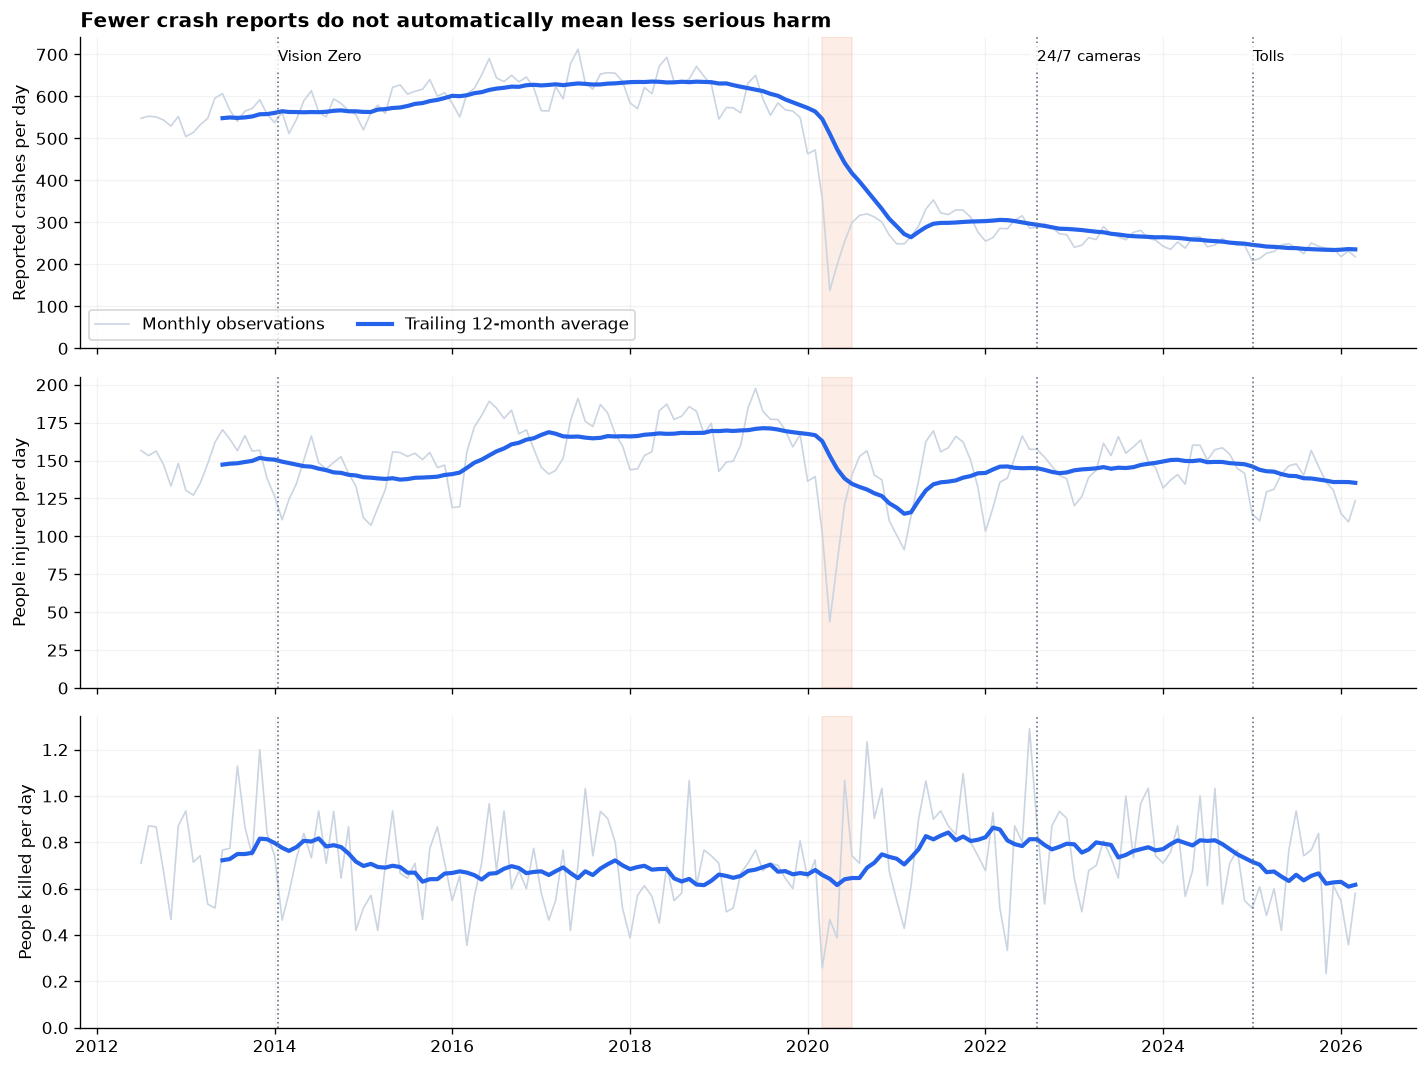

,crashes,harm_crashes,injured,killed
date,,,,
2013-01-01,203742,40273,55128,297
2014-01-01,206046,37704,51230,262
2015-01-01,217708,38040,51369,243
2016-01-01,229833,44239,60317,246
2017-01-01,231007,44674,60656,256
2018-01-01,231564,45767,61940,231
2019-01-01,211486,45439,61391,244
2020-01-01,112918,33361,44615,269
2021-01-01,110558,38809,51785,297


In [6]:
complete = monthly.loc[monthly.complete_month & monthly.complete_outcomes].copy()
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, column, title in zip(axes, ['crashes', 'injured', 'killed'],
                              ['Reported crashes per day', 'People injured per day', 'People killed per day']):
    series = complete[column] / complete.observed_days
    ax.plot(series.index, series, color='#cbd5e1', linewidth=1, label='Monthly observations')
    ax.plot(series.index, series.rolling(12, min_periods=12).mean(), color=BLUE, linewidth=2.5,
            label='Trailing 12-month average')
    ax.set_ylabel(title)
    ax.set_ylim(bottom=0)
    ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2020-07-01'), color=ORANGE, alpha=0.1)
    for label, date in [('Vision Zero', '2014-01-15'), ('24/7 cameras', '2022-08-01'), ('Tolls', '2025-01-05')]:
        ax.axvline(pd.Timestamp(date), color='#64748b', linestyle=':', linewidth=1)
        if ax is axes[0]:
            ax.text(pd.Timestamp(date), 0.96, label, transform=ax.get_xaxis_transform(),
                    ha='left', va='top', fontsize=9, bbox=dict(facecolor='white', edgecolor='none', alpha=.8))
axes[0].legend(loc='lower left', ncol=2)
axes[0].set_title('Fewer crash reports do not automatically mean less serious harm', loc='left')
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.tight_layout()
save_figure(fig, '01_long_run_frequency_and_harm')
annual = daily[measures].resample('YS').sum(min_count=1)
annual['days'] = daily.crashes.resample('YS').size()
annual['complete_year'] = annual.days.eq(np.where(annual.index.is_leap_year, 366, 365))
annual.to_csv(PROCESSED / 'annual_policy_outcomes.csv')
display(annual.loc[annual.complete_year, ['crashes', 'harm_crashes', 'injured', 'killed']].astype(int))

## 7. COVID: normalize by the combined hourly traffic counts
The GitHub combined file replaces the county vehicle-mile denominator. Its counts describe sampled roads, so the result is a **sample-based traffic-adjusted index**, not a citywide per-vehicle or per-mile risk estimate.

### 7a. Clean complete location-days and match crash dates
Automated hours require all four quarter-hour intervals; historical rows already contain hourly volumes. Average repeated observations of the same location/hour, then retain only location-days with all 24 hours. Average counts across locations for each date/hour so adding more counters does not mechanically increase the denominator. `hist_volume` is an overlap reference, not extra traffic to add.

### 7b. Calculate annual ratios using matching dates
For each year: **sum of citywide outcomes on sampled dates / sum of mean-location daily traffic on those same dates**, divided by the pooled ratio over all matched dates. An index of 1 is the pooled baseline. Unsampled dates and zero denominators are omitted; nothing is interpolated. Raw counts below are averaged **per matched date**, because the two years have different numbers of sampled dates.

The 2019–2020 comparison uses each year's observed dates, which differ in road and seasonal composition. 2020 has no complete traffic location-days in some lockdown months, so the comparison does not describe those months. A sensitivity check restricts both years to calendar months observed in both. No causal conclusion follows from the index.

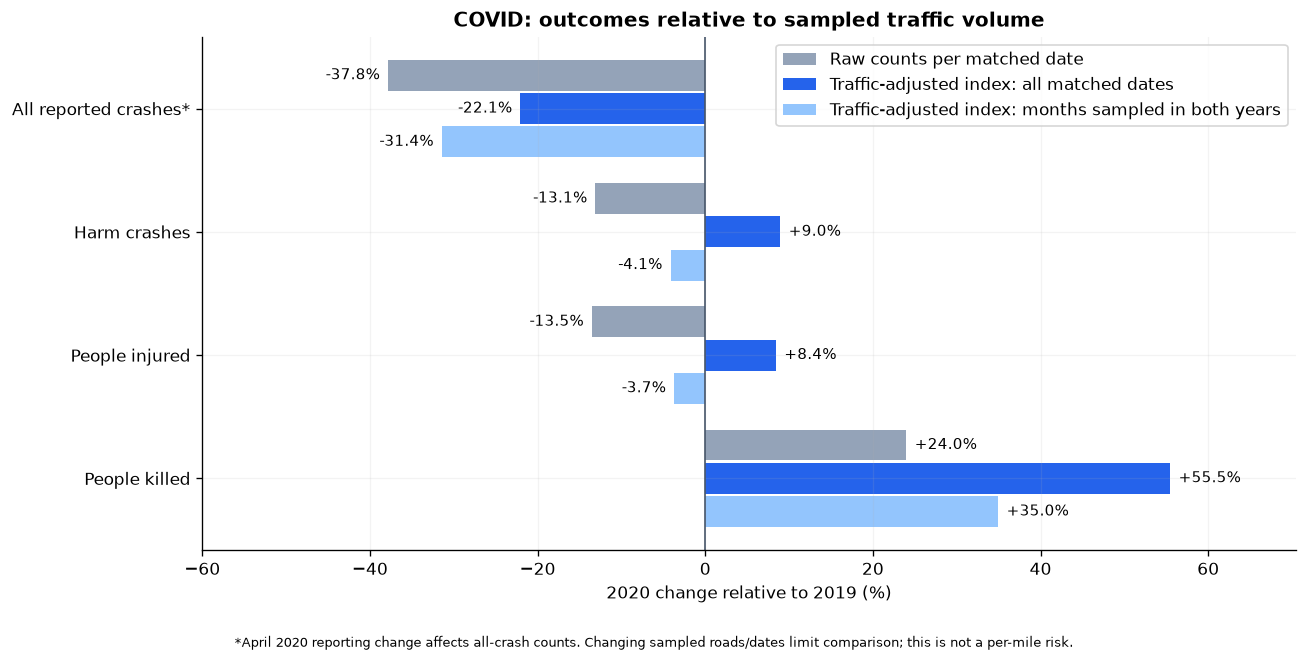

,matched_days,mean_sites,mean_daily_traffic,crashes,harm_crashes,injured,killed,crashes_index,harm_crashes_index,injured_index,killed_index
year,,,,,,,,,,,
2019,316,21.503,12321.882,184078,39285.0,53034.0,214.0,1.054,0.961,0.963,0.826
2020,131,45.122,9826.924,47436,14152.0,19012.0,110.0,0.822,1.047,1.044,1.284
2021,238,5.508,10331.317,74186,26593.0,35436.0,202.0,0.673,1.030,1.019,1.234


,per_matched_date_count_change_percent,traffic_adjusted_index_change_percent,same_month_traffic_adjusted_index_change_percent
crashes,-37.84,-22.06,-31.43
harm_crashes,-13.10,8.96,-4.14
injured,-13.53,8.43,-3.71
killed,23.99,55.47,34.95


**Traffic-adjusted COVID comparison (2020 vs 2019):** mean sampled-location traffic per observed day changed -20.2%. There were 316 matched dates in 2019 and 131 in 2020; 2020 has no traffic-observed dates in Apr, May, Jun, Jul, so the comparison does not describe those months. The harm-crash index changed +9.0% and the fatality index changed +55.5%. Using only months sampled in both years, they changed -4.1% and +35.0%. These are descriptive sample-based indices that are sensitive to which dates and roads were sampled; changing roads, travel mix, and reporting can affect the comparison, and they do not isolate the effect of lockdown policy.

In [7]:
sys.path.insert(0, str(ROOT))
from src.timePattern import load_traffic, normalize_annual_by_traffic, TRAFFIC_FILE, TRAFFIC_SOURCE
traffic_exposure, traffic_report = load_traffic(TRAFFIC_FILE)
covid_rates = normalize_annual_by_traffic(daily, traffic_exposure)
covid_rates.to_csv(PROCESSED / 'annual_crashes_normalized_by_traffic.csv')
metrics = ['crashes', 'harm_crashes', 'injured', 'killed']
pretty = ['All reported crashes*', 'Harm crashes', 'People injured', 'People killed']
rate_columns = [f'{metric}_index' for metric in metrics]

def index_change(rates, year, base=2019):
    return pd.Series((rates.loc[year, rate_columns].to_numpy(dtype=float) /
                      rates.loc[base, rate_columns].to_numpy(dtype=float) - 1) * 100, index=metrics)

# Sum over different numbers of sampled dates is not comparable; use per-date means.
per_matched_day = covid_rates[metrics].div(covid_rates.matched_days, axis=0)
raw_changes = (per_matched_day.loc[2020] / per_matched_day.loc[2019] - 1) * 100
changes = index_change(covid_rates, 2020)
traffic_change = (covid_rates.loc[2020, 'mean_daily_traffic'] /
                  covid_rates.loc[2019, 'mean_daily_traffic'] - 1) * 100
# Seasonal sensitivity: keep only calendar months with traffic observations in both years.
traffic_dates = traffic_exposure.index[traffic_exposure[list(range(24))].sum(axis=1, min_count=24).gt(0)]
traffic_months = {year: set(traffic_dates[traffic_dates.year == year].month) for year in [2019, 2020]}
shared_months = sorted(traffic_months[2019] & traffic_months[2020])
missing_2020_months = sorted(set(range(1, 13)) - traffic_months[2020])
same_month_days = daily.loc[daily.index.year.isin([2019, 2020]) & daily.index.month.isin(shared_months)]
same_month_rates = normalize_annual_by_traffic(same_month_days, traffic_exposure)
same_month_changes = index_change(same_month_rates, 2020)
covid_comparison = pd.DataFrame({'per_matched_date_count_change_percent': raw_changes,
                                 'traffic_adjusted_index_change_percent': changes,
                                 'same_month_traffic_adjusted_index_change_percent': same_month_changes})
covid_comparison.to_csv(OUT / 'covid_raw_vs_traffic_adjusted_changes.csv')
fig, ax = plt.subplots(figsize=(11, 5.5))
positions = np.arange(len(metrics))
bars = [(raw_changes, -.27, '#94a3b8', 'Raw counts per matched date'),
        (changes, 0, BLUE, 'Traffic-adjusted index: all matched dates'),
        (same_month_changes, .27, '#93c5fd', 'Traffic-adjusted index: months sampled in both years')]
for values, shift, color, label in bars:
    ax.barh(positions + shift, values, height=.25, color=color, label=label)
    for position, value in enumerate(values):
        ax.text(value + (1 if value >= 0 else -1), position + shift, f'{value:+.1f}%',
                va='center', ha='left' if value >= 0 else 'right', fontsize=9)
ax.axvline(0, color='#475569', linewidth=1)
ax.set(yticks=positions, yticklabels=pretty, xlabel='2020 change relative to 2019 (%)',
       title='COVID: outcomes relative to sampled traffic volume')
ax.invert_yaxis()
all_values = pd.concat([raw_changes, changes, same_month_changes])
ax.set_xlim(min(-60, all_values.min() - 15), max(55, all_values.max() + 15))
ax.legend(loc='best')
fig.text(.5, .01, '*April 2020 reporting change affects all-crash counts. '
         'Changing sampled roads/dates limit comparison; this is not a per-mile risk.', ha='center', fontsize=8)
fig.tight_layout(rect=(0, .05, 1, 1))
save_figure(fig, '02_covid_traffic_adjusted_changes')
display(covid_rates.loc[[2019, 2020, 2021], ['matched_days', 'mean_sites', 'mean_daily_traffic', *metrics, *rate_columns]].round(3))
display(covid_comparison.round(2))
fatal_ratio = covid_rates.loc[2020, 'killed_index'] / covid_rates.loc[2019, 'killed_index']
month_names = lambda months: ', '.join(pd.Timestamp(2020, month, 1).strftime('%b') for month in months) or 'none'
note(f"**Traffic-adjusted COVID comparison (2020 vs 2019):** mean sampled-location traffic per observed "
     f"day changed {traffic_change:+.1f}%. There were {int(covid_rates.loc[2019, 'matched_days'])} matched "
     f"dates in 2019 and {int(covid_rates.loc[2020, 'matched_days'])} in 2020; 2020 has no traffic-observed "
     f"dates in {month_names(missing_2020_months)}, so the comparison does not describe those months. "
     f"The harm-crash index changed {changes['harm_crashes']:+.1f}% and the fatality index changed "
     f"{changes['killed']:+.1f}%. Using only months sampled in both years, they changed "
     f"{same_month_changes['harm_crashes']:+.1f}% and {same_month_changes['killed']:+.1f}%. "
     "These are descriptive sample-based indices that are sensitive to which dates and roads were sampled; "
     "changing roads, travel mix, and reporting can affect the comparison, and they do not isolate the "
     "effect of lockdown policy.")

### 7c. View sampled traffic, adjusted harm, and matched-date coverage
Traffic is the mean daily count per sampled location on observed dates. The outcome indices divide matched outcome sums by matched traffic sums and use a pooled baseline of 1. The coverage panel makes partial years and sparse years visible. Points summarize each year's available dates, not continuous full-year exposure. The orange band marks 2020–2021 for orientation.

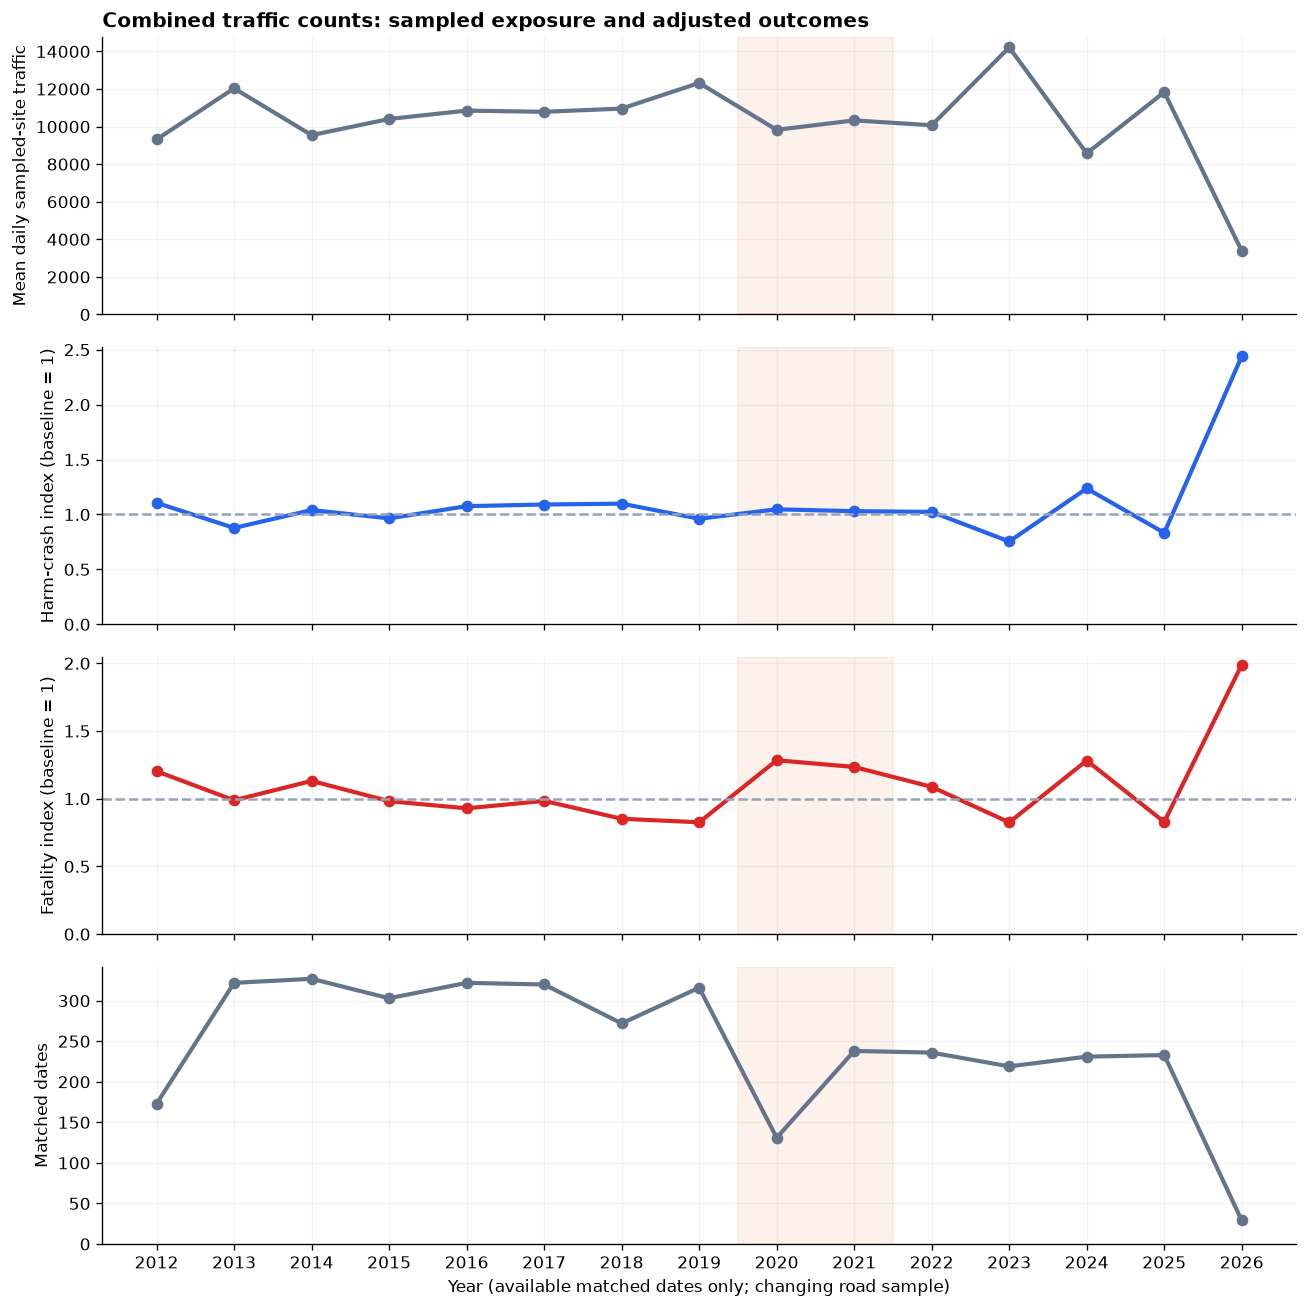

**2021 comparison:** the sampled-traffic-adjusted fatality index changed +49.5% relative to 2019. Check matched-date coverage and road composition before interpreting this difference.

In [8]:
fig, axes = plt.subplots(4, 1, figsize=(11, 11), sharex=True)
for ax, column, title, color in [
    (axes[0], 'mean_daily_traffic', 'Mean daily sampled-site traffic', '#64748b'),
    (axes[1], 'harm_crashes_index', 'Harm-crash index (baseline = 1)', BLUE),
    (axes[2], 'killed_index', 'Fatality index (baseline = 1)', RED),
    (axes[3], 'matched_days', 'Matched dates', '#64748b'),
]:
    ax.plot(covid_rates.index, covid_rates[column], 'o-', linewidth=2.5, color=color)
    ax.axvspan(2019.5, 2021.5, color=ORANGE, alpha=.08)
    ax.set_ylabel(title)
    ax.set_ylim(bottom=0)
for ax in axes[1:3]:
    ax.axhline(1, linestyle='--', color='#94a3b8')
axes[0].set_title('Combined traffic counts: sampled exposure and adjusted outcomes', loc='left')
axes[-1].set_xticks(covid_rates.index)
axes[-1].set_xlabel('Year (available matched dates only; changing road sample)')
fig.tight_layout()
save_figure(fig, '03_covid_traffic_and_indices')
rate_2021 = (covid_rates.loc[2021, 'killed_index'] / covid_rates.loc[2019, 'killed_index'] - 1) * 100
note(f"**2021 comparison:** the sampled-traffic-adjusted fatality index changed {rate_2021:+.1f}% "
     "relative to 2019. Check matched-date coverage and road composition before interpreting this difference.")

## 8. Vision Zero: a segmented count model, with uncertainty
A simple before/after average can confuse a pre-existing trend with a policy change. We fit monthly Poisson mean models through December 2019, including a linear time trend, month-of-year indicators, a post-launch level, and a post-launch trend. The offset is calendar days: coefficients concern **events per day**, not risk per vehicle.

January 2014 is a transition month and is omitted. The first full post-launch month is February. The reported contrast is the model-associated difference **12 months after that first full month**, relative to continuation of the fitted pre-launch trend. Its 95% interval uses heteroskedasticity/autocorrelation-robust covariance (12 monthly lags). This interval is conditional on the model, not a guarantee against confounding.

We also test sensitivity to the March 2016 recording-system change. Vision Zero has only one complete pre-policy calendar year here; the 25 mph change and other interventions are part of the same package. Do not interpret a citywide interrupted series as a randomized policy effect. See [statsmodels GLM](https://www.statsmodels.org/stable/glm.html) and [robust covariance options](https://www.statsmodels.org/stable/_modules/statsmodels/base/covtype.html).

,outcome,recording_adjustment,percent,low,high,pearson_dispersion
0,harm_crashes,False,-7.190,0.879,0.980,10.288
1,harm_crashes,True,-10.058,0.851,0.950,4.534
2,injured,False,-8.708,0.863,0.966,15.561
3,injured,True,-11.829,0.834,0.932,6.047
4,killed,False,-33.936,0.586,0.744,1.002
5,killed,True,-33.997,0.585,0.744,1.015
6,ped_killed,False,-45.352,0.429,0.696,1.077
7,ped_killed,True,-46.097,0.423,0.686,1.088


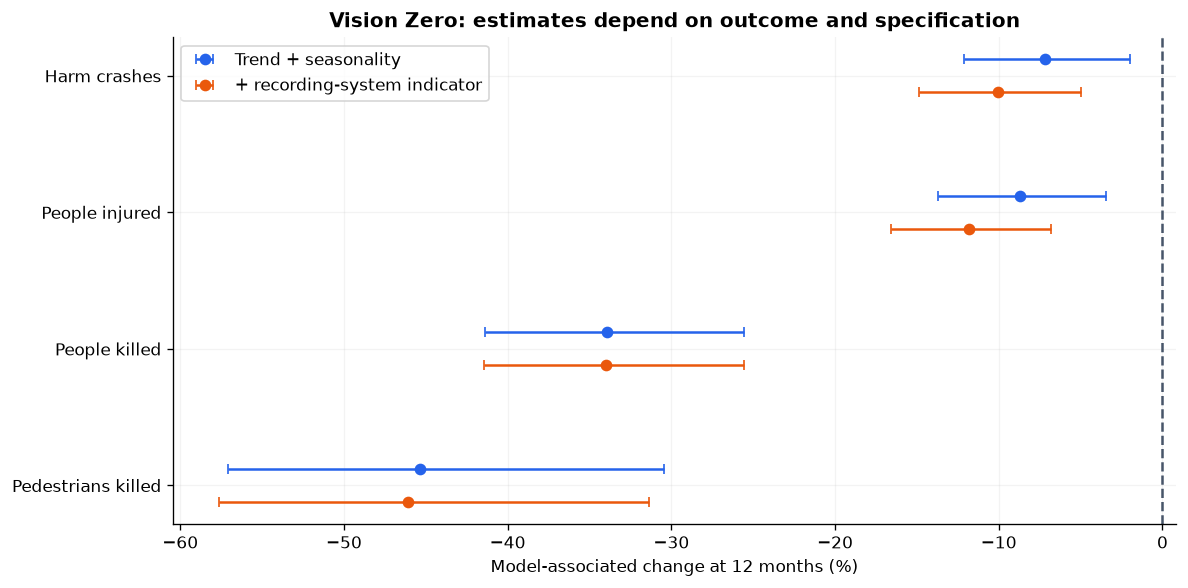

**Vision Zero model:** the fatality contrast at 12 months is -33.9% (95% model interval -41.4% to -25.6%). Adding the recording-change indicator gives -34.0%. This is an association under a chosen pre-trend and seasonality model, not proof of causation. The interval excludes zero under this model; it does not account for confounding or the short pre-period.

In [9]:
def vision_zero_model(outcome, recording_adjustment=False, end='2019-12-01'):
    # Derive model-ready months from the data-preparation table, independently
    # of whether the plotting cell in Section 6 has been run.
    table = monthly.loc[monthly.complete_month & monthly.complete_outcomes].loc[:end].copy()
    month_number = table.index.year * 12 + table.index.month
    table['t'] = month_number - month_number.min()
    table['post'] = (table.index >= '2014-02-01').astype(int)
    # Months since February 2014, the first full post-launch month.
    table['after_t'] = np.maximum(month_number - (2014 * 12 + 2), 0)
    table['recording'] = (table.index >= '2016-03-01').astype(int)
    table = table.loc[table.index != '2014-01-01'].copy()
    formula = f'{outcome} ~ t + C(month_of_year) + post + after_t'
    if recording_adjustment:
        formula += ' + recording'
    model = smf.glm(formula, data=table, family=sm.families.Poisson(),
                    offset=np.log(table.observed_days)).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
    weights = pd.Series(0.0, index=model.params.index)
    weights['post'], weights['after_t'] = 1, 12
    log_ratio = float(weights @ model.params)
    se = float(np.sqrt(weights @ model.cov_params() @ weights))
    ratio, low, high = np.exp([log_ratio, log_ratio - 1.96 * se, log_ratio + 1.96 * se])
    return model, table, {'outcome': outcome, 'recording_adjustment': recording_adjustment,
                          'ratio': ratio, 'low': low, 'high': high,
                          'percent': (ratio - 1) * 100, 'months': len(table),
                          'pearson_dispersion': float(model.pearson_chi2 / model.df_resid)}

vision_rows = [vision_zero_model(outcome, adjust)[2]
               for outcome in ['harm_crashes', 'injured', 'killed', 'ped_killed'] for adjust in [False, True]]
vision_results = pd.DataFrame(vision_rows)
vision_results.to_csv(OUT / 'vision_zero_model_contrasts.csv', index=False)
display(vision_results[['outcome', 'recording_adjustment', 'percent', 'low', 'high', 'pearson_dispersion']].round(3))
fig, ax = plt.subplots(figsize=(10, 5))
labels = {'harm_crashes': 'Harm crashes', 'injured': 'People injured', 'killed': 'People killed', 'ped_killed': 'Pedestrians killed'}
for adjust, shift, color, label in [(False, -.12, BLUE, 'Trend + seasonality'),
                                   (True, .12, ORANGE, '+ recording-system indicator')]:
    subset = vision_results.loc[vision_results.recording_adjustment.eq(adjust)]
    positions = np.arange(len(subset)) + shift
    ax.errorbar(subset.percent, positions,
                xerr=[(subset.ratio - subset.low) * 100, (subset.high - subset.ratio) * 100],
                fmt='o', capsize=3, color=color, label=label)
ax.axvline(0, color='#475569', linestyle='--')
ax.set(yticks=range(4), yticklabels=list(labels.values()),
       xlabel='Model-associated change at 12 months (%)', title='Vision Zero: estimates depend on outcome and specification')
ax.invert_yaxis()
ax.legend(loc='best')
fig.tight_layout()
save_figure(fig, '04_vision_zero_model_sensitivity')
vz = vision_results.loc[(vision_results.outcome == 'killed') & ~vision_results.recording_adjustment].iloc[0]
vz_sensitivity = vision_results.loc[(vision_results.outcome == 'killed') & vision_results.recording_adjustment].iloc[0]
note(f"**Vision Zero model:** the fatality contrast at 12 months is {vz.percent:+.1f}% "
     f"(95% model interval {(vz.low-1)*100:+.1f}% to {(vz.high-1)*100:+.1f}%). "
     f"Adding the recording-change indicator gives {vz_sensitivity.percent:+.1f}%. "
     "This is an association under a chosen pre-trend and seasonality model, not proof of causation. " +
     ('The interval crosses zero, so it is compatible with either direction under this model.'
      if vz.low < 1 < vz.high else
      'The interval excludes zero under this model; it does not account for confounding or the short pre-period.'))

## 9. Did different road users experience the same change?
We compare complete calendar years only and index pedestrian, cyclist, and motorist deaths to 2013 = 100. Absolute counts remain visible in a table, because a large percentage change from a small base can be misleading. There are no walking/cycling/motoring exposure denominators here, so these are **death burdens, not mode-specific risk estimates**.

This is an exploratory subgroup view. No subgroup was selected because it produced a small p-value.

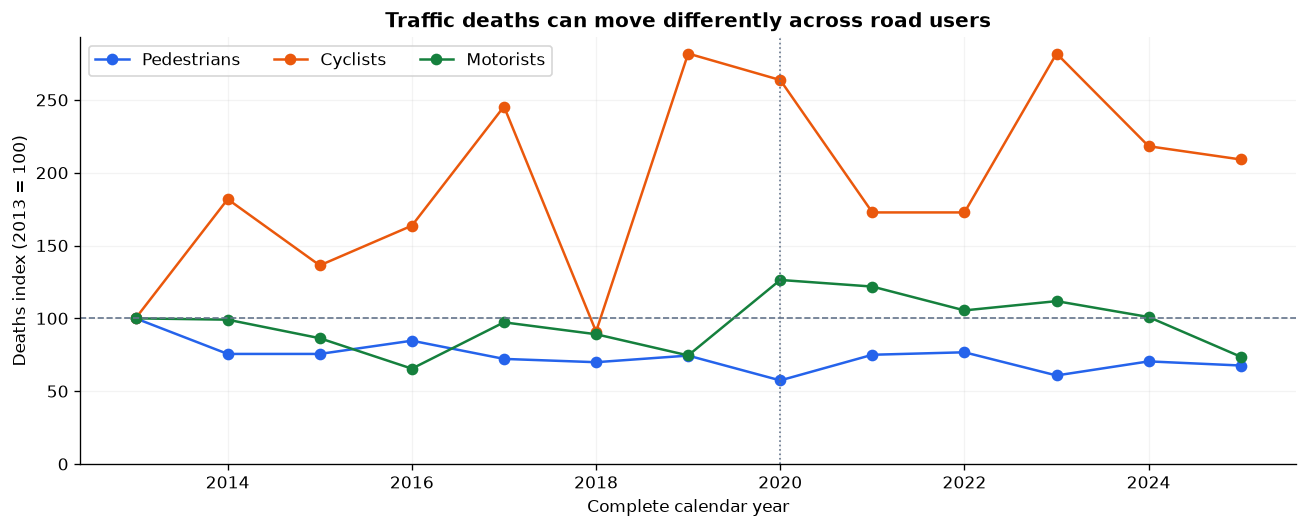

,ped_killed,cyclist_killed,motorist_killed
date,,,
2013-01-01,176,11,110
2014-01-01,133,20,109
2015-01-01,133,15,95
2016-01-01,149,18,72
2017-01-01,127,27,107
2018-01-01,123,10,98
2019-01-01,131,31,82
2020-01-01,101,29,139
2021-01-01,132,19,134


**Road-user differences, 2019 versus 2013:** pedestrian deaths -25.6%; cyclist deaths +181.8%; motorist deaths -25.5%. These changes concern counts, not exposure-adjusted safety; cycling and other travel volumes may have changed.

In [10]:
mode_columns = ['ped_killed', 'cyclist_killed', 'motorist_killed']
full_years = annual.loc[annual.complete_year]
mode_index = full_years[mode_columns].div(full_years.loc['2013-01-01', mode_columns]).mul(100)
fig, ax = plt.subplots(figsize=(11, 4.5))
for column, label, color in zip(mode_columns, ['Pedestrians', 'Cyclists', 'Motorists'], [BLUE, ORANGE, GREEN]):
    ax.plot(mode_index.index.year, mode_index[column], 'o-', label=label, color=color)
ax.axhline(100, color='#64748b', linestyle='--', linewidth=1)
ax.axvline(2020, color='#64748b', linestyle=':', linewidth=1)
ax.set(xlabel='Complete calendar year', ylabel='Deaths index (2013 = 100)',
       title='Traffic deaths can move differently across road users', ylim=(0, None))
ax.legend(ncol=3)
fig.tight_layout()
save_figure(fig, '05_road_user_fatalities')
display(full_years[mode_columns].astype(int))
mode_2019 = (full_years.loc['2019-01-01', mode_columns] / full_years.loc['2013-01-01', mode_columns] - 1) * 100
note('**Road-user differences, 2019 versus 2013:** ' + '; '.join(
    f'{label} deaths {mode_2019[column]:+.1f}%'
    for column, label in zip(mode_columns, ['pedestrian', 'cyclist', 'motorist'])) +
    '. These changes concern counts, not exposure-adjusted safety; cycling and other travel volumes may have changed.')

## 10. 24/7 cameras: compare newly covered hours with previously covered hours
A more focused question is whether harm crashes changed differently during **newly enforceable hours** than during weekday daytime hours. This is more informative than placing one vertical line on the citywide total.

The pre period is August 2021–July 2022. We omit August 2022 as the transition month. The post period is September 2022–August 2023. Each period contains one full set of seasons. Calendar hours are calculated for each group; weekends and weekdays do not have the same number of available hours. An hourly denominator measures time opportunity, **not vehicles or trips**.

This is a citywide comparison of time groups; we do not know which crashes happened at camera locations. Its interpretation requires the groups to have comparable counterfactual trends and no other differential changes. We check pre-trends and extend the outcome comparison as sensitivity, rather than automatically claiming an effect.

harm_crashes  clock_hours  injured  killed  \
post new_hours                                               
0    0               24047.0         4160  30634.0   127.0   
     1               15959.0         4600  22362.0   170.0   
1    0               24508.0         4176  31596.0   115.0   
     1               15285.0         4584  21409.0   158.0   

                harm_per_1000_hours  
post new_hours                       
0    0                     5780.529  
     1                     3469.348  
1    0                     5868.774  
     1                     3334.424

,outcome,ratio_of_rate_ratios,low,high,p_value
0,harm_crashes,0.9460,0.8716,1.0268,0.1844
1,injured,0.9340,0.8560,1.0192,0.1253
2,killed,1.0441,0.6129,1.7789,0.8737


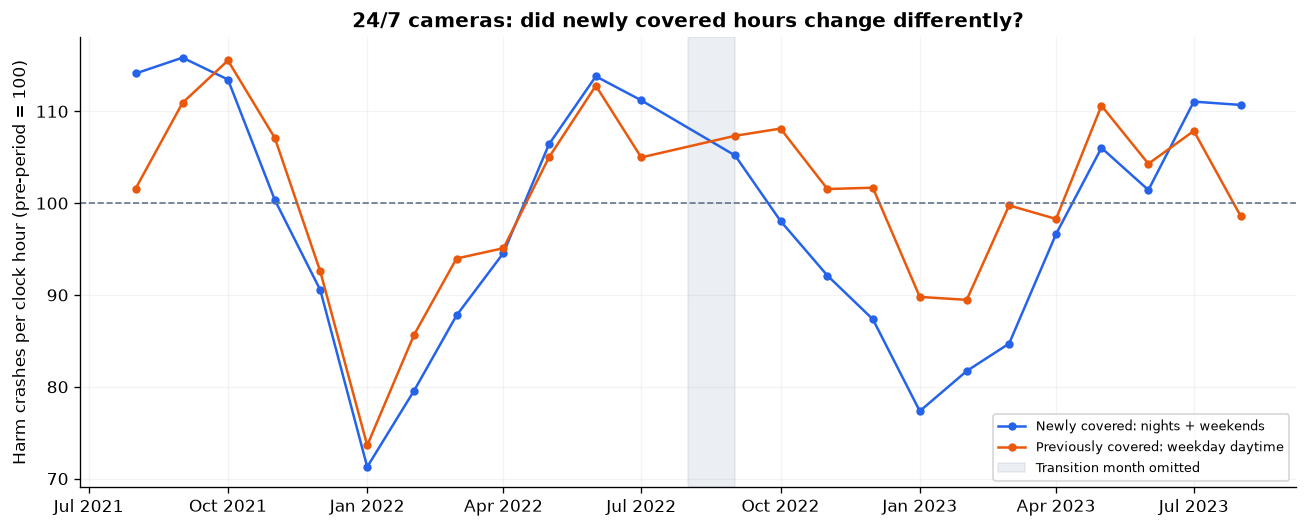

**24/7 camera time-group comparison:** the harm-crash ratio of rate ratios is 0.946 (95% approximate clustered interval 0.872–1.027). That is a -5.4% relative change in newly covered hours versus weekday daytime. The pre-period differential-trend check has p=0.8; it does not detect a differential trend, but cannot establish parallel trends. The comparison does not identify effects specifically at camera sites, and the pandemic recovery can affect time groups differently.

In [11]:
camera_calendar = pd.MultiIndex.from_product([pd.date_range(first_date, last_date), [0, 1]],
                                             names=['date', 'new_hours'])
cam = camera_daily.reindex(camera_calendar, fill_value=0).reset_index()
is_weekend = cam.date.dt.dayofweek.ge(5)
cam['clock_hours'] = np.where(cam.new_hours.eq(1), np.where(is_weekend, 24, 8), np.where(is_weekend, 0, 16))
cam = cam.loc[cam.clock_hours.gt(0)].copy()
cam['month'] = cam.date.dt.to_period('M').dt.to_timestamp()
cam_month = cam.groupby(['month', 'new_hours'])[[*measures, 'clock_hours']].sum(min_count=1).reset_index()
cam_month['post'] = cam_month.month.between('2022-09-01', '2023-08-01').astype(int)
cam_month['pre'] = cam_month.month.between('2021-08-01', '2022-07-01').astype(int)
cam_window = cam_month.loc[cam_month.pre.eq(1) | cam_month.post.eq(1)].copy()
cam_window['month_label'] = cam_window.month.dt.strftime('%Y-%m')
cam_window['treated'] = cam_window['new_hours']
assert cam_window.groupby('post').month.nunique().eq(12).all()
cam_window.to_csv(PROCESSED / 'camera_policy_comparison_panel.csv', index=False)
cam_summary = cam_window.groupby(['post', 'new_hours'])[['harm_crashes', 'clock_hours', 'injured', 'killed']].sum()
cam_summary['harm_per_1000_hours'] = cam_summary.harm_crashes / cam_summary.clock_hours * 1000
display(cam_summary.round(3))
# Month fixed effects compare time groups within each month. Cluster uncertainty by month.
# There are 24 time clusters; intervals should be treated as approximate.
camera_results = []
for outcome in ['harm_crashes', 'injured', 'killed']:
    model = smf.glm(f'{outcome} ~ treated + C(month_label) + treated:post', data=cam_window,
                    family=sm.families.Poisson(), offset=np.log(cam_window.clock_hours)).fit(
                        cov_type='cluster', cov_kwds={'groups': cam_window['month_label']})
    coefficient = model.params['treated:post']
    interval = model.conf_int().loc['treated:post']
    camera_results.append({'outcome': outcome, 'ratio_of_rate_ratios': np.exp(coefficient),
                           'low': np.exp(interval.iloc[0]), 'high': np.exp(interval.iloc[1]),
                           'p_value': model.pvalues['treated:post']})
camera_results = pd.DataFrame(camera_results)
camera_results.to_csv(OUT / 'camera_policy_model_contrasts.csv', index=False)
display(camera_results.round(4))
# Pre-period differential trend check, with month fixed effects.
pre_cam = cam_window.loc[cam_window.pre.eq(1)].copy()
pre_cam['t'] = pre_cam.month.dt.year * 12 + pre_cam.month.dt.month
pre_cam['t'] -= pre_cam.t.min()
pretrend = smf.glm('harm_crashes ~ treated + C(month_label) + treated:t', data=pre_cam,
                   family=sm.families.Poisson(), offset=np.log(pre_cam.clock_hours)).fit(
                       cov_type='cluster', cov_kwds={'groups': pre_cam.month_label})
pretrend_p = float(pretrend.pvalues['treated:t'])
fig, ax = plt.subplots(figsize=(11, 4.5))
for group, label, color in [(1, 'Newly covered: nights + weekends', BLUE),
                             (0, 'Previously covered: weekday daytime', ORANGE)]:
    plot = cam_month.loc[cam_month.new_hours.eq(group) & cam_month.month.between('2021-08-01', '2023-08-01')].copy()
    base = cam_summary.loc[(0, group), 'harm_per_1000_hours']
    # Remove the omitted transition month from the plotted series as well.
    plot = plot.loc[plot.month.ne('2022-08-01')]
    values = plot.harm_crashes / plot.clock_hours * 1000 / base * 100
    ax.plot(plot.month, values, 'o-', label=label, color=color, markersize=4)
ax.axvspan(pd.Timestamp('2022-08-01'), pd.Timestamp('2022-09-01'), color='#94a3b8', alpha=.18,
           label='Transition month omitted')
ax.axhline(100, color='#64748b', linestyle='--', linewidth=1)
ax.set(ylabel='Harm crashes per clock hour (pre-period = 100)',
       title='24/7 cameras: did newly covered hours change differently?')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.legend(loc='best', fontsize=8)
fig.tight_layout()
save_figure(fig, '06_camera_time_groups')
cam_main = camera_results.loc[camera_results.outcome.eq('harm_crashes')].iloc[0]
note(f"**24/7 camera time-group comparison:** the harm-crash ratio of rate ratios is "
     f"{cam_main.ratio_of_rate_ratios:.3f} (95% approximate clustered interval {cam_main.low:.3f}–{cam_main.high:.3f}). "
     f"That is a {(cam_main.ratio_of_rate_ratios-1)*100:+.1f}% relative change in newly covered hours versus weekday daytime. "
     f"The pre-period differential-trend check has p={pretrend_p:.3g}; "
     + ('it flags a pre-existing group difference in trends, weakening a causal interpretation.'
        if pretrend_p < .05 else 'it does not detect a differential trend, but cannot establish parallel trends.') +
     ' The comparison does not identify effects specifically at camera sites, and the pandemic recovery can affect time groups differently.')

## 11. Check whether the camera comparison depends on the chosen window
We repeat the comparison using six-month windows and wider 18-month windows, still omitting the August 2022 transition month. Month fixed effects absorb citywide monthly shocks, but the choice of window can still matter. A second check uses a placebo cutoff in August 2021; a nonzero placebo warns that this design can pick up changes unrelated to the 2022 expansion.

These are sensitivity diagnostics, not a search for the most significant specification. All results are retained.
Six- and 18-month windows are not season-balanced; their differences can also reflect changing seasonal mixes.

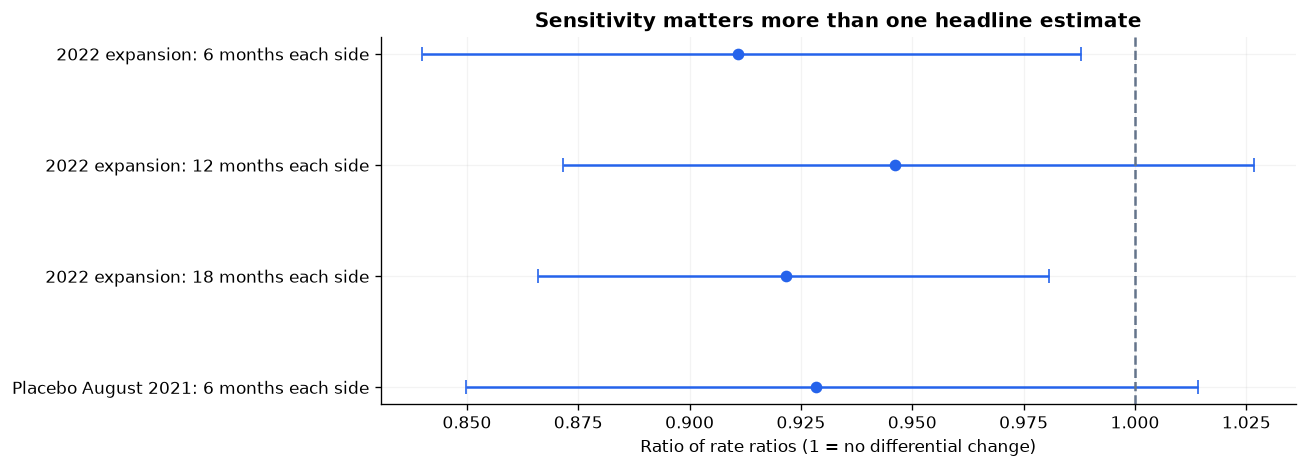

,comparison,ratio,low,high
0,2022 expansion: 6 months each side,0.9109,0.8400,0.9879
1,2022 expansion: 12 months each side,0.9460,0.8716,1.0268
2,2022 expansion: 18 months each side,0.9216,0.8661,0.9807
3,Placebo August 2021: 6 months each side,0.9283,0.8497,1.0142


**Camera window sensitivity:** the six-month 2022 estimate is 0.911 and the August 2021 placebo, which has no policy change, is 0.928. Six-month windows compare different seasons, so a placebo of similar size means those windows can pick up seasonal or recovery differences between time groups. Only the 12-month comparison is season-balanced.

In [12]:
def time_group_contrast(cutoff, months, label):
    event = pd.Timestamp(cutoff)
    table = cam_month.loc[
        cam_month.month.between(event - pd.DateOffset(months=months), event - pd.DateOffset(months=1)) |
        cam_month.month.between(event + pd.DateOffset(months=1), event + pd.DateOffset(months=months))
    ].copy()
    table['treated'] = table.new_hours
    table['post'] = table.month.gt(event).astype(int)
    table['month_label'] = table.month.dt.strftime('%Y-%m')
    model = smf.glm('harm_crashes ~ treated + C(month_label) + treated:post', data=table,
                    family=sm.families.Poisson(), offset=np.log(table.clock_hours)).fit(
                        cov_type='cluster', cov_kwds={'groups': table.month_label})
    interval = model.conf_int().loc['treated:post']
    return {'comparison': label, 'ratio': np.exp(model.params['treated:post']),
            'low': np.exp(interval.iloc[0]), 'high': np.exp(interval.iloc[1])}

camera_sensitivity = pd.DataFrame([
    time_group_contrast('2022-08-01', 6, '2022 expansion: 6 months each side'),
    time_group_contrast('2022-08-01', 12, '2022 expansion: 12 months each side'),
    time_group_contrast('2022-08-01', 18, '2022 expansion: 18 months each side'),
    time_group_contrast('2021-08-01', 6, 'Placebo August 2021: 6 months each side'),
])
camera_sensitivity.to_csv(OUT / 'camera_sensitivity_and_placebo.csv', index=False)
fig, ax = plt.subplots(figsize=(11, 4))
positions = np.arange(len(camera_sensitivity))
ax.errorbar(camera_sensitivity.ratio, positions,
            xerr=[camera_sensitivity.ratio-camera_sensitivity.low,
                  camera_sensitivity.high-camera_sensitivity.ratio],
            fmt='o', capsize=4, color=BLUE)
ax.axvline(1, color='#64748b', linestyle='--')
ax.set(yticks=positions, yticklabels=camera_sensitivity.comparison,
       xlabel='Ratio of rate ratios (1 = no differential change)', title='Sensitivity matters more than one headline estimate')
ax.invert_yaxis()
fig.tight_layout()
save_figure(fig, '07_camera_window_sensitivity')
display(camera_sensitivity.round(4))
six_month, placebo = camera_sensitivity.ratio.iloc[[0, 3]]
note(f"**Camera window sensitivity:** the six-month 2022 estimate is {six_month:.3f} and the August 2021 "
     f"placebo, which has no policy change, is {placebo:.3f}. Six-month windows compare different seasons, "
     "so a placebo of similar size means those windows can pick up seasonal or recovery differences "
     "between time groups. Only the 12-month comparison is season-balanced.")

## 12. What the new street data add—and what they cannot tell us
The combined road table lets us describe the distribution of reported harm by an inventory attribute. We use **2017–2019** to avoid the 2020 reporting break and reduce the time gap to the largely 2018-vintage street snapshot. We report the share of known-status reported crashes that were harm crashes, not crashes per vehicle or per kilometre.

Street names can span several segments. Mixed-speed names stay separate; the chart does not relabel their median as an exact crash-segment speed. A high conditional harm share is not proof that a travel-speed category causes more crashes. Road type, exposure, reporting, and selection can all differ.

,crashes,harm_crashes,killed,harm_share,fatalities_per_1000_harm_crashes
road_context,,,,,
Inventory speed 25 or lower,116938,26529.0,110.0,22.687,4.146
Inventory speed 26–35,4481,911.0,6.0,20.330,6.586
Inventory speed above 35,369,89.0,1.0,24.119,11.236
Mixed inventory speeds,149682,34731.0,239.0,23.204,6.881
Unmatched,402587,73620.0,375.0,18.288,5.094


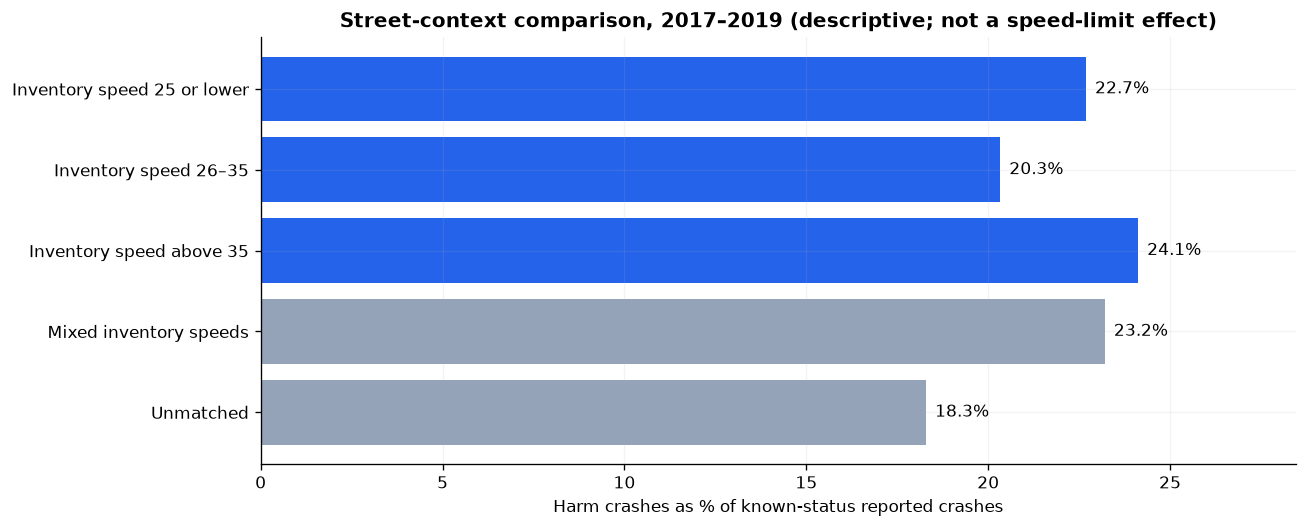

In [13]:
road_table = road_monthly.loc[(slice('2017-01-01', '2019-12-01'), slice(None)), :].groupby(level='road_context').sum()
road_table['harm_share'] = road_table.harm_crashes / road_table.known_harm * 100
road_table['fatalities_per_1000_harm_crashes'] = road_table.killed / road_table.harm_crashes * 1000
road_table.to_csv(OUT / 'street_context_outcomes_2017_2019.csv')
display(road_table[['crashes', 'harm_crashes', 'killed', 'harm_share', 'fatalities_per_1000_harm_crashes']].round(3))
order = ['Inventory speed 25 or lower', 'Inventory speed 26–35', 'Inventory speed above 35',
         'Mixed inventory speeds', 'Matched, no speed value', 'Unmatched']
plot = road_table.reindex(order).dropna(subset=['harm_share'])
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.barh(plot.index, plot.harm_share, color=[BLUE if 'Inventory speed' in i else '#94a3b8' for i in plot.index])
for i, value in enumerate(plot.harm_share):
    ax.text(value + .25, i, f'{value:.1f}%', va='center')
ax.invert_yaxis()
ax.set(xlabel='Harm crashes as % of known-status reported crashes',
       title='Street-context comparison, 2017–2019 (descriptive; not a speed-limit effect)')
ax.set_xlim(0, plot.harm_share.max() * 1.18)
fig.tight_layout()
save_figure(fig, '08_street_context_descriptive')

## 13. Combined traffic coverage and normalization limits
Section 7 and the time-pattern charts use the same combined hourly file. Counts remain intermittent observations at selected roads. Averaging locations addresses counter numbers, but does not make the road sample representative of NYC. Coverage is shown explicitly and is joined to the daily crash panel. These indices are descriptive; the policy models continue to use counts with calendar-time exposure.

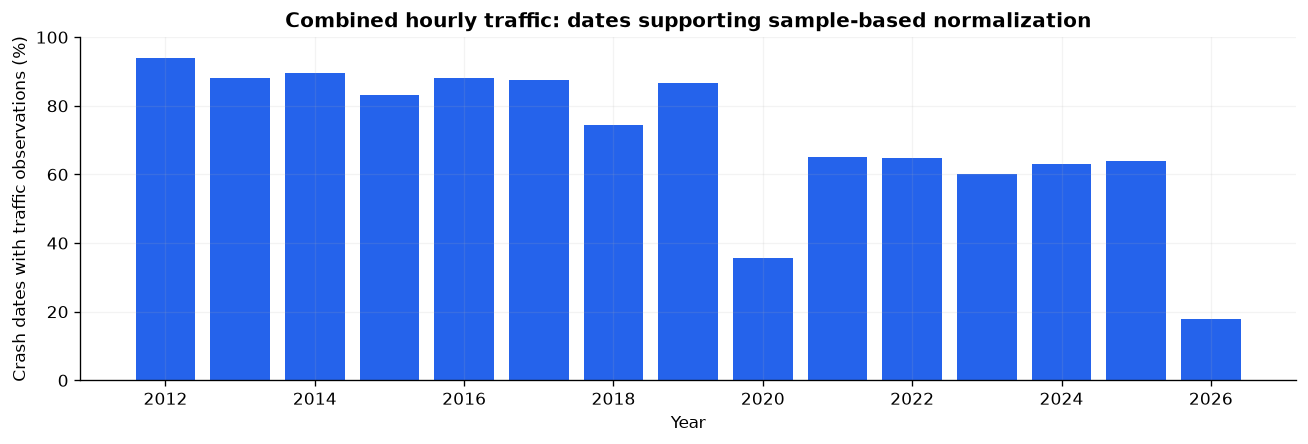

,days,traffic_days,mean_sampled_locations,coverage_percent
date,,,,
2012-01-01,184,173,30.0,94.0
2013-01-01,365,322,7.4,88.2
2014-01-01,365,327,21.9,89.6
2015-01-01,365,303,22.9,83.0
2016-01-01,366,322,13.5,88.0
2017-01-01,365,320,19.3,87.7
2018-01-01,365,272,7.1,74.5
2019-01-01,365,316,21.2,86.6
2020-01-01,366,131,45.1,35.8


**Traffic coverage:** complete location-days overlap 3,672 of 5,094 crash dates. Section 7 normalizes only these dates using the combined file. The changing road sample does not provide a citywide per-vehicle or per-mile risk denominator.

In [14]:
traffic_hash = hashlib.sha256(TRAFFIC_FILE.read_bytes()).hexdigest()
manifest['files'].append({'path': str(TRAFFIC_FILE.relative_to(ROOT)),
    'url': TRAFFIC_SOURCE, 'sha256': traffic_hash,
    'note': 'Combined historical/automated hourly counts; complete location-days; sample-based indices.'})
(OUT / 'source_manifest.json').write_text(json.dumps(manifest, indent=2))
coverage = daily[['crashes', 'harm_crashes', 'injured', 'killed']].copy()
coverage['sampled_locations'] = traffic_exposure['sites']
coverage['mean_site_daily_count'] = traffic_exposure[list(range(24))].sum(axis=1, min_count=24)
coverage['traffic_observed'] = coverage.mean_site_daily_count.gt(0).fillna(False).astype(int)
coverage.to_csv(PROCESSED / 'daily_crashes_with_traffic_coverage.csv')
coverage_year = coverage.resample('YS').agg(days=('crashes', 'size'),
    traffic_days=('traffic_observed', 'sum'), mean_sampled_locations=('sampled_locations', 'mean'))
coverage_year['coverage_percent'] = coverage_year.traffic_days / coverage_year.days * 100
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(coverage_year.index.year, coverage_year.coverage_percent, color=BLUE)
ax.set(xlabel='Year', ylabel='Crash dates with traffic observations (%)', ylim=(0, 100),
       title='Combined hourly traffic: dates supporting sample-based normalization')
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
fig.tight_layout()
save_figure(fig, '09_traffic_sample_coverage')
display(coverage_year.round(1))
note(f"**Traffic coverage:** complete location-days overlap {int(coverage.traffic_observed.sum()):,} "
     f"of {len(coverage):,} crash dates. Section 7 normalizes only these dates using the combined file. "
     "The changing road sample does not provide a citywide per-vehicle or per-mile risk denominator.")

## 14. A recent-policy context check: congestion pricing
We compare January–June 2025 with the same months in 2024 by borough, using harm-crash counts per calendar day. This is **not an evaluation of the tolling zone**: all of Manhattan is not the zone, some highways are exempt, and the supplied street CSV has no zone geometry. The table provides a recent descriptive pattern and makes the geographic limitation explicit.

Both years have the same months, but one contains a leap day. Date-based rates handle that. Missing boroughs are preserved and reported, rather than silently discarded. Spillovers and changes in geocoding could affect a comparison across boroughs.

In [15]:
recent = borough_daily.reset_index()
recent = recent.loc[recent.date.dt.year.isin([2024, 2025]) & recent.date.dt.month.le(6)].copy()
recent['year'] = recent.date.dt.year
borough_change = recent.groupby(['borough', 'year'])[['harm_crashes', 'injured', 'killed']].sum().unstack('year')
for year in [2024, 2025]:
    days = len(pd.date_range(f'{year}-01-01', f'{year}-06-30'))
    borough_change[('harm_per_day', year)] = borough_change[('harm_crashes', year)] / days
borough_change[('change_percent', '')] = (borough_change[('harm_per_day', 2025)] /
                                          borough_change[('harm_per_day', 2024)] - 1) * 100
borough_change.to_csv(OUT / 'borough_context_2024_2025.csv')
display(borough_change.round(2))

harm_crashes         injured         killed       harm_per_day  \
year                  2024    2025    2024    2025   2024  2025         2024   
borough                                                                        
BRONX               2089.0  2168.0  2854.0  2884.0   16.0  10.0        11.48   
BROOKLYN            4640.0  5068.0  6062.0  6524.0   29.0  31.0        25.49   
MANHATTAN           2181.0  2544.0  2573.0  2952.0   13.0  14.0        11.98   
QUEENS              3639.0  3443.0  4739.0  4392.0   19.0  18.0        19.99   
STATEN ISLAND        469.0   493.0   593.0   710.0    4.0   2.0         2.58   
UNKNOWN             6472.0  3883.0  9411.0  5893.0   58.0  27.0        35.56   

                     change_percent  
year            2025                 
borough                              
BRONX          11.98           4.36  
BROOKLYN       28.00           9.83  
MANHATTAN      14.06          17.29  
QUEENS         19.02          -4.86  
STATEN ISLAND   2.72           5.70  
UNKNOWN        21.45         -39.67

## 15. Diagnostics, limitations, and a presentation-ready story
The report keeps every tested outcome and sensitivity specification. It does not select a policy conclusion from one small p-value. Model intervals quantify conditional sampling uncertainty; they do not remove unmeasured exposure changes, policing/reporting changes, pandemic recovery, regression to the mean, or concurrent interventions.

The next cell writes the actual numerical findings plus a short presentation outline. The checks reconcile source totals, require nonnegative outcomes, preserve unmapped roads, and verify complete-month and camera-period definitions. No final partial-year total is compared with a full year.

In [16]:
assert audit['raw_crashes'] == 2_269_187, 'Unexpected source version: review the source manifest.'
assert monthly.crashes.sum() == daily.crashes.sum()
assert borough_daily.crashes.sum() == daily.crashes.sum()
assert road_monthly.crashes.sum() == daily.crashes.sum()
assert camera_daily.crashes.sum() == daily.crashes.sum() - audit['missing_time']
assert not complete.observed_days.ne(complete.calendar_days).any()
assert not vision_results[['ratio', 'low', 'high']].isna().any().any()
assert not camera_results[['ratio_of_rate_ratios', 'low', 'high']].isna().any().any()
assert np.isclose(covid_rates.traffic.sum(), coverage.mean_site_daily_count.where(coverage.traffic_observed.eq(1)).sum())
assert int(covid_rates.matched_days.sum()) == int(coverage.traffic_observed.sum())
for metric in ['crashes', 'harm_crashes', 'injured', 'killed']:
    assert np.isclose(np.average(covid_rates[f'{metric}_index'], weights=covid_rates.traffic), 1)
checks = {
    'Archive hashes verified': True,
    'Collision IDs unique': duplicate_ids == 0,
    'Street join did not multiply crashes': True,
    'Daily/monthly/borough/road totals reconcile': True,
    'Unknown outcomes and roads remain explicit': True,
    'Monthly policy models exclude partial months': True,
    'Camera main comparison has 12 full months per period': True,
    'Combined traffic and outcomes use matching observed dates': True,
    'Traffic-weighted pooled outcome indices equal one': True,
    'Notebook and interpretations executed from source data': True,
}
display(pd.Series(checks).to_frame('passed'))
(OUT / 'validation_checks.json').write_text(json.dumps(checks, indent=2))
summary = '# NYC crash policy analysis: findings from the executed notebook\n\n'
summary += '\n\n'.join(FINDINGS)
summary += '\n\n## What to say in a five-minute presentation\n\n'
summary += ('1. Start with the distinction between crash reports and serious harm.\n'
            '2. Show the COVID raw-versus-traffic-adjusted comparison, the months without traffic data, and the April 2020 reporting change.\n'
            '3. Show the Vision Zero contrast with its interval and specification sensitivity.\n'
            '4. Use the 24/7 camera time-group comparison as a focused policy question; show pre-trend and placebo diagnostics.\n'
            '5. Conclude with what the data support, what remains uncertain, and why a citywide causal risk estimate needs better exposure/control data.\n')
summary += '\n## Claims to avoid\n\n'
summary += ('- Do not call every drop in police reports a fall in actual crashes.\n'
            '- Do not label a conditional injury share or clock-hour rate as injury risk per vehicle.\n'
            '- Do not use snapshot inventory SPEED as the historical legal speed limit.\n'
            '- Do not label the all-Manhattan comparison as a toll-zone treatment effect.\n'
            '- Do not interpret a policy-timed association as a proven causal effect.\n')
summary += '\n\n## Outputs\n\n' + '\n'.join(f'- {name}.png' for name in FIGURES)
(OUT / 'findings.md').write_text(summary)
(OUT / 'policy_results.json').write_text(json.dumps({
    'covid_annual_traffic_index_changes': changes.to_dict(),
    'covid_annual_raw_per_matched_date_changes': raw_changes.to_dict(),
    'covid_same_month_traffic_index_changes': same_month_changes.to_dict(),
    'covid_mean_daily_sampled_traffic_change_percent': float(traffic_change),
    'covid_fatality_index_ratio': float(fatal_ratio),
    'vision_zero': vision_results.to_dict('records'),
    'camera_main': camera_results.to_dict('records'),
    'camera_sensitivity': camera_sensitivity.to_dict('records'),
    'camera_pretrend_p': pretrend_p,
}, indent=2))
print(f'Validated {audit["raw_crashes"]:,} crashes; exported {len(FIGURES)} figures and combined analysis tables.')
display(Markdown(summary))

,passed
Archive hashes verified,True
Collision IDs unique,True
Street join did not multiply crashes,True
Daily/monthly/borough/road totals reconcile,True
Unknown outcomes and roads remain explicit,True
Monthly policy models exclude partial months,True
Camera main comparison has 12 full months per period,True
Combined traffic and outcomes use matching observed dates,True
Traffic-weighted pooled outcome indices equal one,True
Notebook and interpretations executed from source data,True


Validated 2,269,187 crashes; exported 9 figures and combined analysis tables.


# NYC crash policy analysis: findings from the executed notebook

**Data actually used:** 2,269,187 crashes, from July 01, 2012 to June 11, 2026. The street-context join matches 52.1% of all crashes; 30.5% have an unknown borough. Unmatched records remain in the citywide analysis. Partial endpoint months are excluded from monthly models.

**Missing-data finding:** months with more than 0.1% missing injury/fatality fields are excluded from the main monthly figures and models: Apr 2026, May 2026, Jun 2026. Their raw records remain in the exported panels with completeness flags. Missing deaths are never filled with zero.

**Traffic-adjusted COVID comparison (2020 vs 2019):** mean sampled-location traffic per observed day changed -20.2%. There were 316 matched dates in 2019 and 131 in 2020; 2020 has no traffic-observed dates in Apr, May, Jun, Jul, so the comparison does not describe those months. The harm-crash index changed +9.0% and the fatality index changed +55.5%. Using only months sampled in both years, they changed -4.1% and +35.0%. These are descriptive sample-based indices that are sensitive to which dates and roads were sampled; changing roads, travel mix, and reporting can affect the comparison, and they do not isolate the effect of lockdown policy.

**2021 comparison:** the sampled-traffic-adjusted fatality index changed +49.5% relative to 2019. Check matched-date coverage and road composition before interpreting this difference.

**Vision Zero model:** the fatality contrast at 12 months is -33.9% (95% model interval -41.4% to -25.6%). Adding the recording-change indicator gives -34.0%. This is an association under a chosen pre-trend and seasonality model, not proof of causation. The interval excludes zero under this model; it does not account for confounding or the short pre-period.

**Road-user differences, 2019 versus 2013:** pedestrian deaths -25.6%; cyclist deaths +181.8%; motorist deaths -25.5%. These changes concern counts, not exposure-adjusted safety; cycling and other travel volumes may have changed.

**24/7 camera time-group comparison:** the harm-crash ratio of rate ratios is 0.946 (95% approximate clustered interval 0.872–1.027). That is a -5.4% relative change in newly covered hours versus weekday daytime. The pre-period differential-trend check has p=0.8; it does not detect a differential trend, but cannot establish parallel trends. The comparison does not identify effects specifically at camera sites, and the pandemic recovery can affect time groups differently.

**Camera window sensitivity:** the six-month 2022 estimate is 0.911 and the August 2021 placebo, which has no policy change, is 0.928. Six-month windows compare different seasons, so a placebo of similar size means those windows can pick up seasonal or recovery differences between time groups. Only the 12-month comparison is season-balanced.

**Traffic coverage:** complete location-days overlap 3,672 of 5,094 crash dates. Section 7 normalizes only these dates using the combined file. The changing road sample does not provide a citywide per-vehicle or per-mile risk denominator.

## What to say in a five-minute presentation

1. Start with the distinction between crash reports and serious harm.
2. Show the COVID raw-versus-traffic-adjusted comparison, the months without traffic data, and the April 2020 reporting change.
3. Show the Vision Zero contrast with its interval and specification sensitivity.
4. Use the 24/7 camera time-group comparison as a focused policy question; show pre-trend and placebo diagnostics.
5. Conclude with what the data support, what remains uncertain, and why a citywide causal risk estimate needs better exposure/control data.

## Claims to avoid

- Do not call every drop in police reports a fall in actual crashes.
- Do not label a conditional injury share or clock-hour rate as injury risk per vehicle.
- Do not use snapshot inventory SPEED as the historical legal speed limit.
- Do not label the all-Manhattan comparison as a toll-zone treatment effect.
- Do not interpret a policy-timed association as a proven causal effect.


## Outputs

- 01_long_run_frequency_and_harm.png
- 02_covid_traffic_adjusted_changes.png
- 03_covid_traffic_and_indices.png
- 04_vision_zero_model_sensitivity.png
- 05_road_user_fatalities.png
- 06_camera_time_groups.png
- 07_camera_window_sensitivity.png
- 08_street_context_descriptive.png
- 09_traffic_sample_coverage.png

## Sources and reproducibility
- **Collision data:** City of New York, [Motor Vehicle Collisions—Crashes](https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-Crashes/h9gi-nx95). Course-provided snapshot, documented in the repository as updated July 31, 2026. Preliminary and subject to revision.
- **GitHub snapshot:** [pinned commit f92bea87](https://github.com/ericmao2007/SSMU-Data-Challenge-I/tree/f92bea87dff7ee7a57e41b4af85535f571d1f5a1/data). Archive hashes and exact URLs are in `source_manifest.json`.
- **Road inventory definitions:** [NYS Streets data dictionary](https://gis.ny.gov/system/files/documents/2023/07/streets_data_dictionary.pdf). The supplied CSV is not a historical speed-limit panel.
- **Traffic normalization:** [Combined hourly traffic archive](https://github.com/ericmao2007/SSMU-Data-Challenge-I/blob/f92bea87dff7ee7a57e41b4af85535f571d1f5a1/data/other/Combined_Traffic_Volume_Counts_hourly.zip). Historical and automated counts are converted to complete location-days. Source hashes and filtering are recorded in the manifest and Section 7.
- **Policy and reporting dates:** official links in Section 3.
- **Statistical implementation:** [statsmodels GLM documentation](https://www.statsmodels.org/stable/glm.html).
- **AI assistance:** analysis/code were prepared with Codex and reviewed with Claude Code at the user's request. The competition README asks participants to disclose AI use and include a link to the conversation in their presentation citations.

**Rerun:** install `requirements-analysis.txt`, then run all cells in this notebook; or execute `python tools/run_policy_notebook.py` from the repository root. Cached inputs permit offline reruns. The browser report embeds its figures and folds code under “Show code.”

### Dataset citation (APA 7th edition)
City of New York—Motor Vehicle Collisions—Crashes. (n.d.). Data.Gov. Retrieved October 14, 2026, from http://catalog.data.gov/dataset/motor-vehicle-collisions-crashes